# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [16]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import os

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [17]:
# Load the CSV file from the dataset folder.
# This works in the provided folder structure and in Google Colab.

possible_paths = [
    "dataset/Lab_11_QnA_Dataset.csv",
    "/content/dataset/Lab_11_QnA_Dataset.csv",
    "Lab_11_QnA_Dataset.csv",
    "/content/Lab_11_QnA_Dataset.csv"
]

csv_path = next((path for path in possible_paths if os.path.exists(path)), None)

if csv_path is None:
    raise FileNotFoundError(
        "Dataset not found. Make sure Lab_11_QnA_Dataset.csv is inside the dataset folder."
    )

df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [18]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase and remove missing questions
df = df.dropna(subset=["question", "answer_id"]).copy()
df["question"] = df["question"].astype(str).str.lower().str.strip()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

print("Input tensor shape:", X.shape)
print("Target tensor shape:", y.shape)

Input tensor shape: torch.Size([168, 11])
Target tensor shape: torch.Size([168])


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [19]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        # Keep the original token mask so padding is excluded from attention.
        mask = (x != 0)
        x, _ = self.rnn(self.emb(x))
        scores = self.att(x).squeeze(-1)

        # Ignore padding tokens when calculating attention.
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=1)

        context = (x * weights.unsqueeze(-1)).sum(1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(100):
    optimizer.zero_grad()
    predictions, _ = model(X)
    loss = nn.functional.cross_entropy(predictions, y) # calculate loss to reduce it
    loss.backward() # backpropagation to update parameters
    optimizer.step() # update parameters

    if (epoch + 1) % 20 == 0:
        accuracy = (predictions.argmax(dim=1) == y).float().mean()
        print(f"Epoch {epoch + 1}/100 - Loss: {loss.item():.4f} - Accuracy: {accuracy.item():.2%}")

print("Training finished!")

Epoch 20/100 - Loss: 1.2049 - Accuracy: 69.05%
Epoch 40/100 - Loss: 0.1980 - Accuracy: 97.02%
Epoch 60/100 - Loss: 0.0286 - Accuracy: 100.00%
Epoch 80/100 - Loss: 0.0071 - Accuracy: 100.00%
Epoch 100/100 - Loss: 0.0040 - Accuracy: 100.00%
Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

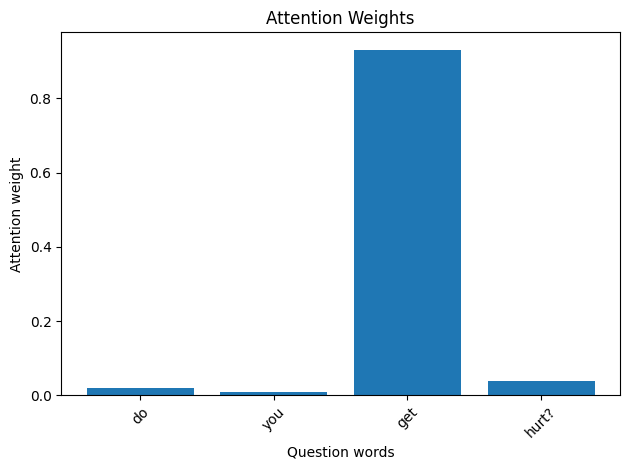

In [21]:
# Show attention for the first question.
question = df["question"].iloc[0]
sequence = tokenizer.texts_to_sequences([question])
question_tensor = torch.tensor(
    pad_sequences(sequence, maxlen=X.shape[1], padding="post"),
    dtype=torch.long
)

with torch.no_grad():
    prediction, weights = model(question_tensor)

words = question.split()
plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.xlabel("Question words")
plt.ylabel("Attention weight")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Predicted answer: I don't have a body.
Highest attention word: get
Attention weight: 0.9314


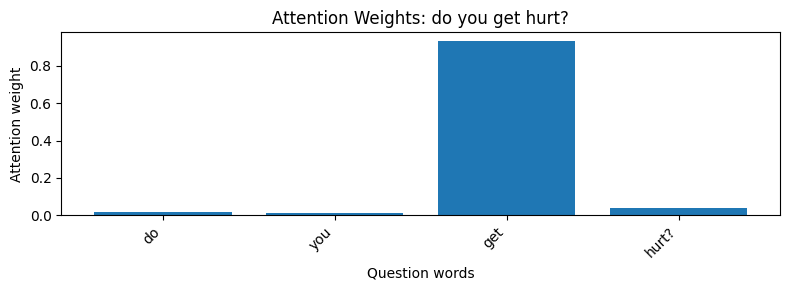

Question: how old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention word: old
Attention weight: 0.5847


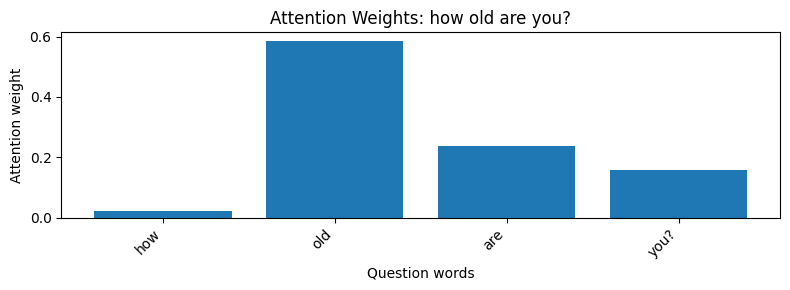

Question: how do you feel about artificial intelligence?
Predicted answer: The world of technology is fascinating.
Highest attention word: about
Attention weight: 0.9337


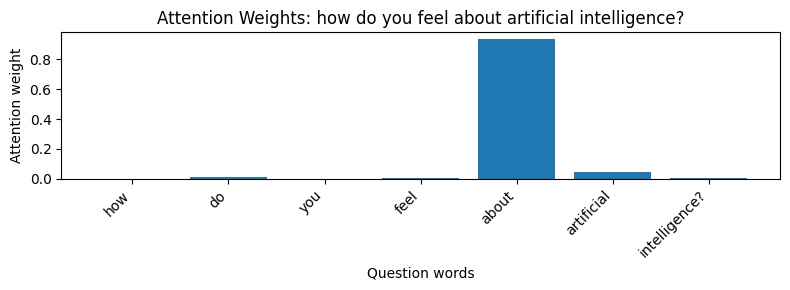

Observation: The words receiving the highest attention are often meaningful words related to the question's topic. However, attention weights show where the model focuses; they do not always prove that a word is the only important one.


In [22]:
import numpy as np

# Task 1: Visualize attention weights for three different questions.

selected_indices = [0, 24, 126]

for index in selected_indices:
    question = df["question"].iloc[index]
    sequence = tokenizer.texts_to_sequences([question])
    question_tensor = torch.tensor(
        pad_sequences(sequence, maxlen=X.shape[1], padding="post"),
        dtype=torch.long
    )

    with torch.no_grad():
        prediction, weights = model(question_tensor)

    words = question.split()
    word_weights = weights[0, :len(words)].tolist()
    highest_index = int(np.argmax(word_weights))

    print("Question:", question)
    print("Predicted answer:", df.loc[df["answer_id"] == int(prediction.argmax()), "answer"].iloc[0])
    print("Highest attention word:", words[highest_index])
    print("Attention weight:", round(word_weights[highest_index], 4))

    plt.figure(figsize=(8, 3))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Question words")
    plt.ylabel("Attention weight")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print(
    "Observation: The words receiving the highest attention are often meaningful "
    "words related to the question's topic. However, attention weights show where "
    "the model focuses; they do not always prove that a word is the only important one."
)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: How do you feel about artificial intelligence?
Highest attention word: about
Attention weight: 0.9337


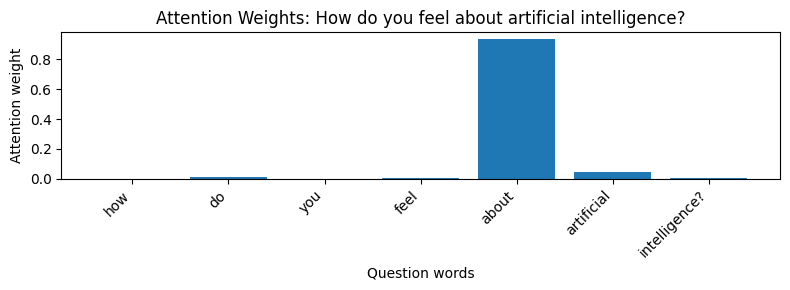

Question: What is your opinion about AI?
Highest attention word: opinion
Attention weight: 0.9862


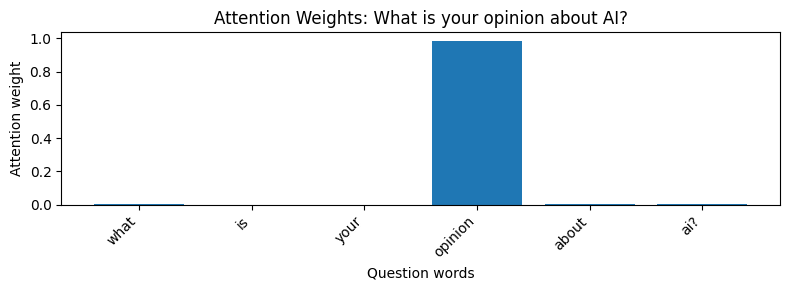

Answer: The questions have similar meanings, so the model may focus on related words such as 'feel', 'opinion', 'artificial', and 'intelligence'. The exact weights can differ because the wording is different. This shows that attention assigns importance to words based on their context in each question.


In [23]:
import numpy as np

# Task 2: Compare attention for two questions with similar meanings.

similar_questions = [
    "How do you feel about artificial intelligence?",
    "What is your opinion about AI?"
]

for question in similar_questions:
    sequence = tokenizer.texts_to_sequences([question.lower()])
    question_tensor = torch.tensor(
        pad_sequences(sequence, maxlen=X.shape[1], padding="post"),
        dtype=torch.long
    )

    with torch.no_grad():
        prediction, weights = model(question_tensor)

    # Keep only words that are present in the tokenized sequence.
    words = question.lower().split()
    word_weights = weights[0, :len(words)].tolist()
    highest_index = int(np.argmax(word_weights))

    print("Question:", question)
    print("Highest attention word:", words[highest_index])
    print("Attention weight:", round(word_weights[highest_index], 4))

    plt.figure(figsize=(8, 3))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Question words")
    plt.ylabel("Attention weight")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print(
    "Answer: The questions have similar meanings, so the model may focus on "
    "related words such as 'feel', 'opinion', 'artificial', and 'intelligence'. "
    "The exact weights can differ because the wording is different. This shows "
    "that attention assigns importance to words based on their context in each question."
)